# 12. Paper guía: réplica, limitaciones y ablación

El paper guía es Celik (2025), que propone el modelo Celik-HC. Lo elegimos por tres motivos: es el único estudio del corpus con código público completo, reporta la mayor accuracy en TrashNet (99.40 %) y combina dos de las familias más usadas en la literatura, EfficientNet e Inception, con una fusión multinivel. En este capítulo lo describimos, replicamos su resultado con su propio código, cuantificamos dos limitaciones y aislamos el aporte de sus componentes.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "entregable2" / "src").exists())
E2 = ROOT / "entregable2"
for p in (E2 / "analisis", E2):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st
from IPython.display import display, Markdown
import figuras as FG
FG.setup()
RES = E2 / "results"
SUM = RES / "summary"
COMP = RES / "complementario"

## 12.1 Referencia y descripción del modelo

Celik, G. (2025). Multi-layer feature fusion for high-accuracy solid waste classification using a hybrid deep learning model. *The Visual Computer*, *41*, 10227–10249. https://doi.org/10.1007/s00371-025-04031-3. Código: https://github.com/GaffariCelik/SolidWasteClassification

**Arquitectura.** Una imagen $x \in \mathbb{R}^{224 \times 224 \times 3}$ entra en paralelo a EfficientNet-B0 e InceptionV3, ambas con pesos de ImageNet. De cada red se toman dos mapas de rasgos profundos:

- **EfficientNet-B0:** las salidas de `block6d_add` y `top_activation`;
- **InceptionV3:** las salidas de `mixed8` y `mixed10`.

Cada mapa se reduce con *global average pooling* y los cuatro vectores se concatenan. Esa es la *hypercolumn*:

$$h(x) = \big[\mathrm{GAP}(F^{E}_{6d}(x)) \,\|\, \mathrm{GAP}(F^{E}_{\text{top}}(x)) \,\|\, \mathrm{GAP}(F^{I}_{8}(x)) \,\|\, \mathrm{GAP}(F^{I}_{10}(x))\big] \in \mathbb{R}^{d_1 + d_2}.$$

Cinco capas densas con ReLU (512, 256, 128, 64 y 6 neuronas) se entrenan con entropía cruzada. Después, la salida de 64 dimensiones $z(x)$ se usa como *embedding* para un clasificador XGBoost, $\hat y = \mathrm{XGB}(z(x))$, que suma árboles ajustados al gradiente de la pérdida, $F_{m+1}(x) = F_m(x) - \gamma\, h_m(x)$.

**Supuestos del modelo.** Los rasgos de distintas profundidades y de dos arquitecturas son complementarios. Un clasificador por *boosting* sobre el *embedding* separa mejor las clases que la *softmax*. El conjunto de prueba es una muestra independiente de la distribución de interés.

**Relación con el benchmark.** Celik-HC comparte con RWCNet la idea de fusionar dos CNN preentrenadas y con GFN la de combinar escalas. Es el único modelo que añade un clasificador de *machine learning* clásico. En el benchmark ocupa el cuarto lugar (capítulo 13).

## 12.2 Réplica bajo las condiciones originales

**Protocolo original.** Reprodujimos el código oficial en PyTorch:

- partición aleatoria 80/20 sobre las 2527 imágenes con `random_state = 32` (506 de prueba);
- 40 épocas, Adam con tasa de 1e-3, lote de 128, sin aumento de datos;
- XGBoost con `random_state = 101`;
- la época se elige con la mayor accuracy sobre el mismo 20 % que se reporta como prueba, igual que en el repositorio.

**Protocolo estricto.** Es idéntico, salvo que la época se elige con un 10 % de validación interno separado del entrenamiento. El 20 % de prueba se evalúa una sola vez.

Cada protocolo se repitió con 5 semillas.

**Criterio de éxito, fijado antes de ejecutar.** La réplica tiene éxito si la accuracy publicada (0.994) cae dentro del IC 95 % bootstrap de la accuracy de prueba de la corrida.

In [2]:
rep = pd.read_csv(SUM / "replicacion_paper_guia.csv")
def resumen(g):
    m, s, n = g.mean(), g.std(ddof=1), len(g)
    h = st.t.ppf(0.975, n - 1) * s / np.sqrt(n)
    return f"{m:.3f} ± {s:.3f} [{m - h:.3f}, {m + h:.3f}]"
tab = rep.groupby("protocol").agg(
    accuracy_XGBoost=("accuracy", resumen), f1_macro=("f1_macro", resumen),
    accuracy_softmax=("accuracy_head", resumen), mejor_epoca=("best_epoch", "mean"),
    corridas_con_exito=("reportado_en_ic", "sum")).loc[["original", "estricto"]]
display(tab)
display(rep[["protocol", "seed", "best_epoch", "selection_accuracy", "accuracy", "ic_lo", "ic_hi", "reportado_en_ic"]].round(4))

,accuracy_XGBoost,f1_macro,accuracy_softmax,mejor_epoca,corridas_con_exito
protocol,,,,,
original,"0.925 ± 0.005 [0.919, 0.930]","0.904 ± 0.007 [0.895, 0.914]","0.941 ± 0.005 [0.935, 0.946]",20.8,0
estricto,"0.896 ± 0.010 [0.884, 0.909]","0.872 ± 0.006 [0.865, 0.879]","0.909 ± 0.013 [0.893, 0.925]",23.0,0


,protocol,seed,best_epoch,selection_accuracy,accuracy,ic_lo,ic_hi,reportado_en_ic
0,original,0,13,0.9368,0.9249,0.9012,0.9466,False
1,estricto,0,21,0.9557,0.8972,0.8696,0.9229,False
2,original,1,15,0.9407,0.9209,0.8972,0.9427,False
3,estricto,1,27,0.9458,0.8953,0.8676,0.9209,False
4,original,2,29,0.9486,0.9308,0.9071,0.9506,False
5,estricto,2,4,0.9458,0.8854,0.8577,0.9130,False
6,original,3,16,0.9387,0.9269,0.9032,0.9466,False
7,estricto,3,34,0.9507,0.9130,0.8874,0.9368,False
8,original,4,31,0.9387,0.9190,0.8933,0.9427,False
9,estricto,4,29,0.9113,0.8913,0.8636,0.9170,False


**La réplica no tiene éxito.** El criterio no se cumple en ninguna de las 10 corridas. Con el protocolo original obtenemos una accuracy de 0.925 ± 0.005: 6.9 puntos por debajo de la publicada, y el IC 95 % de cada corrida excluye 0.994. La discrepancia no se explica por casi-duplicados entre las particiones del protocolo original: solo 1 de las 506 imágenes de prueba tiene un casi-duplicado en entrenamiento (`replication/protocol.json`).

Atribuimos la brecha a causas que el experimento no separa:

- el cambio de Keras a PyTorch, con pesos de ImageNet de distinta procedencia;
- un preprocesamiento no documentado en el repositorio;
- la versión del conjunto de datos y las semillas.

La brecha es grande (unas 14 desviaciones estándar entre semillas), lo que vuelve poco probable que se deba solo a la aleatoriedad del entrenamiento.

In [3]:
o = rep[rep.protocol == "original"].set_index("seed"); e = rep[rep.protocol == "estricto"].set_index("seed")
filas = []
for met, nombre in [("accuracy", "Accuracy (XGBoost)"), ("f1_macro", "F1 macro (XGBoost)"), ("accuracy_head", "Accuracy (softmax)")]:
    d = (o[met] - e[met]).to_numpy()
    t = st.ttest_1samp(d, 0)
    h = st.t.ppf(0.975, len(d) - 1) * d.std(ddof=1) / np.sqrt(len(d))
    filas.append({"métrica": nombre, "original − estricto": d.mean(), "IC 95 % inf": d.mean() - h, "IC 95 % sup": d.mean() + h,
                  "t": t.statistic, "p": t.pvalue, "d_z": d.mean() / d.std(ddof=1)})
display(pd.DataFrame(filas).round(4))
print("¿La accuracy de selección coincide con la de prueba de la softmax en el protocolo original?",
      bool(np.allclose(o.selection_accuracy, o.accuracy_head)))

,métrica,original − estricto,IC 95 % inf,IC 95 % sup,t,p,d_z
0,Accuracy (XGBoost),0.0281,0.014,0.0421,5.5526,0.0051,2.4832
1,F1 macro (XGBoost),0.0324,0.022,0.0428,8.6705,0.0010,3.8776
2,Accuracy (softmax),0.0320,0.012,0.0521,4.4354,0.0114,1.9836


¿La accuracy de selección coincide con la de prueba de la softmax en el protocolo original? True


## 12.3 Limitación 1: selección de la época con el conjunto de prueba

El código oficial guarda el modelo de la época con mayor accuracy sobre el conjunto que luego reporta como prueba. La celda anterior muestra el mecanismo: en el protocolo original, la accuracy usada para elegir la época es idéntica a la accuracy de prueba de la *softmax*, porque ambas se calculan sobre el mismo conjunto. Elegir la época de esta forma infla la accuracy en **2.8 puntos** (IC 95 % [1.4, 4.2], t pareada con 5 semillas, $p = 0.005$) y el F1 macro en **3.2 puntos** (IC [2.2, 4.3], $p = 0.001$). Este sesgo afecta a cualquier modelo seleccionado así, no solo al paper guía. Por eso nuestro protocolo común elige la época con validación (capítulo 11).

## 12.4 Limitación 2: fragilidad ante ruido gaussiano

La segunda limitación es la que sirve de punto de partida para el modelo propio de la etapa siguiente. Ante ruido gaussiano de $\sigma = 0.05$ sobre la imagen normalizada, el F1 macro de Celik-HC cae de 0.914 a 0.255. La cuantificamos con un IC 95 % bootstrap que remuestrea grupos de casi-duplicados del conjunto de prueba, con 2000 remuestreos, promediando las 8 semillas en cada remuestreo. Para verificar si la limitación es propia del paper guía o compartida por su familia, repetimos el cálculo en los otros modelos del benchmark.

La limitación se declaró al planear la etapa siguiente, sobre perturbaciones fijadas en el preregistro. El análisis de este capítulo es exploratorio.

In [4]:
ci = pd.read_csv(COMP / "robustez_caidas_ic.csv")
r05 = ci[ci.perturbacion == "ruido_0.05"].set_index("model")
orden = ["Celik-HC", "MbXception", "FocusRCNet", "ResMsCapsule", "RWCNet", "GFN", "ViT-B16"]
display(r05.loc[orden, ["caida_f1", "ic_lo", "ic_hi"]].round(3).rename(columns={"caida_f1": "caída de F1 (σ = 0.05)"}))
rb = pd.read_csv(SUM / "robustez.csv")
w = rb[rb.perturbacion.isin(["limpio", "ruido_0.05"])].pivot_table(index=["model", "seed"], columns="perturbacion", values="f1_macro")
w["caida"] = w["limpio"] - w["ruido_0.05"]
cd = w["caida"].unstack(0)
filas = []
for m in ["MbXception", "FocusRCNet", "ResMsCapsule", "RWCNet", "GFN", "ViT-B16"]:
    d = (cd["Celik-HC"] - cd[m]).to_numpy()
    filas.append({"contraste": f"Celik-HC − {m}", "diferencia de caída": d.mean(), "p_t": st.ttest_1samp(d, 0).pvalue})
f = pd.DataFrame(filas)
from statsmodels.stats.multitest import multipletests
f["p_Holm"] = multipletests(f.p_t, method="holm")[1]
display(f.round(4))

,caída de F1 (σ = 0.05),ic_lo,ic_hi
model,,,
Celik-HC,0.659,0.630,0.684
MbXception,0.639,0.598,0.678
FocusRCNet,0.666,0.625,0.702
ResMsCapsule,0.480,0.443,0.518
RWCNet,0.297,0.263,0.332
GFN,0.124,0.098,0.154
ViT-B16,0.044,0.025,0.066


,contraste,diferencia de caída,p_t,p_Holm
0,Celik-HC − MbXception,0.0193,0.6712,1.0000
1,Celik-HC − FocusRCNet,-0.0078,0.7887,1.0000
2,Celik-HC − ResMsCapsule,0.1783,0.0016,0.0048
3,Celik-HC − RWCNet,0.3614,0.0001,0.0003
4,Celik-HC − GFN,0.5342,0.0000,0.0000
5,Celik-HC − ViT-B16,0.6148,0.0000,0.0000


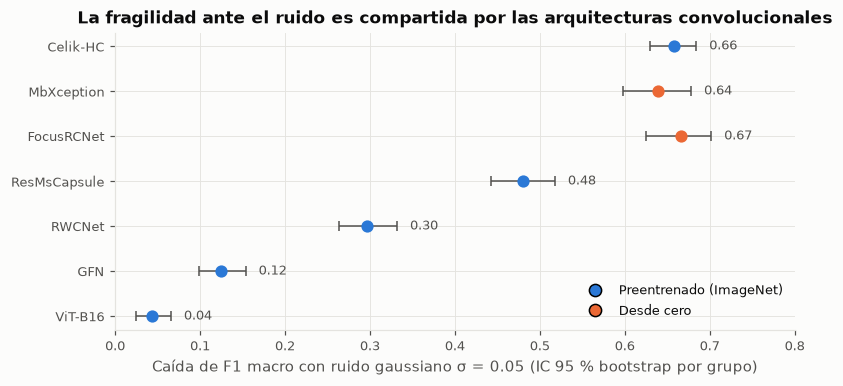

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
y = np.arange(len(orden))
for i, m in enumerate(orden):
    r = r05.loc[m]
    ax.errorbar(r.caida_f1, i, xerr=[[r.caida_f1 - r.ic_lo], [r.ic_hi - r.caida_f1]], fmt="o", color=FG.color_regimen(m),
                ecolor=FG.INK2, elinewidth=1, capsize=3, ms=7)
    ax.text(r.ic_hi + 0.015, i, f"{r.caida_f1:.2f}", va="center", fontsize=8.5, color=FG.INK2)
ax.set_yticks(y, orden); ax.invert_yaxis(); ax.set_xlim(0, 0.8)
ax.set_xlabel("Caída de F1 macro con ruido gaussiano σ = 0.05 (IC 95 % bootstrap por grupo)")
ax.set_title("La fragilidad ante el ruido es compartida por las arquitecturas convolucionales")
FG.leyenda_regimen(ax, loc="lower right"); plt.tight_layout(); plt.show()

La limitación no es exclusiva del paper guía:

- **CNN pura:** MbXception, FocusRCNet, ResMsCapsule y RWCNet pierden entre 0.30 y 0.67 de F1, con intervalos que excluyen cero, igual que los tres modelos base del capítulo 5.
- **Atención global:** los dos modelos con un codificador Transformer degradan mucho menos. GFN pierde 0.12 y ViT-B16 0.04.
- **Prueba pareada:** la caída de Celik-HC supera a la de los demás modelos, salvo MbXception y FocusRCNet, con $p$ Holm < 0.05.

La fragilidad ante el ruido es una propiedad de las arquitecturas convolucionales entrenadas sin ruido en el aumento de datos. Esto la vuelve un candidato natural para el modelo propio, en línea con los mecanismos M1 (destilación), M2 (entrenamiento con ruido) y M4 (atención global) de la sección 10.8.

## 12.5 Aporte de XGBoost

El artículo atribuye a XGBoost una mejora de la clasificación final. En nuestras 8 semillas del benchmark comparamos, sobre las mismas corridas, la salida de XGBoost con la de la cabeza *softmax* que la produce.

In [6]:
xs = pd.read_csv(SUM / "celik_xgb_vs_softmax.csv")
d = (xs.f1_macro_xgb - xs.f1_macro_softmax).to_numpy()
h = st.t.ppf(0.975, 7) * d.std(ddof=1) / np.sqrt(8)
print(f"F1 macro: XGBoost {xs.f1_macro_xgb.mean():.3f} frente a softmax {xs.f1_macro_softmax.mean():.3f}; "
      f"diferencia {d.mean():.3f} [IC 95 % {d.mean() - h:.3f}, {d.mean() + h:.3f}], t pareada p = {st.ttest_1samp(d, 0).pvalue:.3f}, "
      f"Wilcoxon p = {st.wilcoxon(d).pvalue:.3f}")

F1 macro: XGBoost 0.914 frente a softmax 0.924; diferencia -0.010 [IC 95 % -0.023, 0.002], t pareada p = 0.092, Wilcoxon p = 0.109


XGBoost no mejora a la *softmax*: la diferencia media es negativa (−0.010) y su intervalo incluye el cero. En la réplica también empeora la accuracy: −1.6 puntos con el protocolo original y −1.2 con el estricto. Mantuvimos XGBoost como salida oficial de Celik-HC para respetar el modelo publicado.

## 12.6 Ablación del paper guía

Aislamos cinco componentes con 8 semillas por variante y el mismo protocolo y la misma configuración de hiperparámetros del modelo completo:

- **sin_hypercolumn:** solo la última capa de cada red, sin fusión multinivel;
- **capas_intermedias:** las capas del «Model_1» del artículo (`block4c`, `block5c`, `mixed6` y `mixed7`);
- **solo_efficientnet:** sin InceptionV3;
- **solo_inception:** sin EfficientNet-B0;
- **sin_preentrenamiento:** ambas redes desde cero, con la tasa base y la normalización de ese régimen.

La diferencia es *modelo completo − variante*: un valor positivo indica que el componente retirado aporta. Las 5 comparaciones forman una familia con corrección de Holm. La ablación no figura en el preregistro y se declara exploratoria. Se ejecutó en la RTX 4060 y el modelo completo en la A100, con el mismo código, configuración y semillas.

In [7]:
ab = pd.read_csv(SUM / "ablacion.csv")
ab = ab[ab.variante.str.startswith("Celik-HC/")].copy()
ab["variante"] = ab.variante.str.replace("Celik-HC/", "")
display(ab[["variante", "f1_media", "f1_de", "dif_media", "ic_t_lo", "ic_t_hi", "p_t_holm", "p_wilcoxon_holm",
            "relevante_y_significativa"]].round(4))
eq = pd.read_csv(COMP / "equivalencia_ablacion.csv") if (COMP / "equivalencia_ablacion.csv").exists() else None
if eq is not None:
    display(eq[eq.variante.str.startswith("Celik-HC/")].round(4))

,variante,f1_media,f1_de,dif_media,ic_t_lo,ic_t_hi,p_t_holm,p_wilcoxon_holm,relevante_y_significativa
0,capas_intermedias,0.9092,0.0165,0.0047,-0.0104,0.0199,1.0000,1.0000,False
1,sin_hypercolumn,0.9090,0.0121,0.0049,-0.0108,0.0207,1.0000,1.0000,False
2,sin_preentrenamiento,0.8289,0.0196,0.0851,0.0647,0.1054,0.0001,0.0391,True
3,solo_efficientnet,0.9148,0.0096,-0.0008,-0.0182,0.0166,1.0000,1.0000,False
4,solo_inception,0.8873,0.0139,0.0266,0.0075,0.0457,0.0526,0.1562,False


,base,variante,f1_variante,f1_de,f1_completo,ece_variante,dif_media,ic_t_lo,ic_t_hi,d_z,p_t,p_wilcoxon,p_tost,ic90_lo,ic90_hi,p_t_holm_familia,decision
0,Celik-HC,Celik-HC/capas_intermedias,0.9092,0.0165,0.9139,0.0573,0.0047,-0.0104,0.0199,0.2602,0.4857,0.5469,0.0242,-0.0074,0.0169,1.0000,equivalente (TOST ±δ)
1,Celik-HC,Celik-HC/sin_hypercolumn,0.9090,0.0121,0.9139,0.0576,0.0049,-0.0108,0.0207,0.2615,0.4836,0.5469,0.0292,-0.0077,0.0176,1.0000,equivalente (TOST ±δ)
2,Celik-HC,Celik-HC/sin_preentrenamiento,0.8289,0.0196,0.9139,0.1312,0.0851,0.0647,0.1054,3.4958,0.0000,0.0078,0.9999,0.0688,0.1014,0.0001,significativa y relevante
3,Celik-HC,Celik-HC/solo_efficientnet,0.9148,0.0096,0.9139,0.0550,-0.0008,-0.0182,0.0166,-0.0400,0.9131,1.0000,0.0176,-0.0148,0.0131,1.0000,equivalente (TOST ±δ)
4,Celik-HC,Celik-HC/solo_inception,0.8873,0.0139,0.9139,0.0794,0.0266,0.0075,0.0457,1.1662,0.0131,0.0391,0.7811,0.0113,0.0420,0.0526,no concluyente


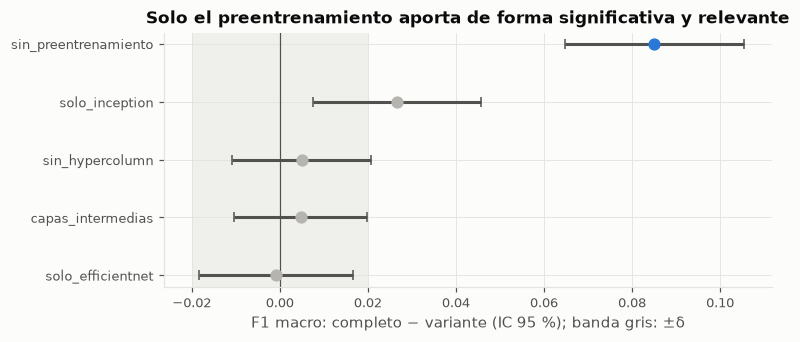

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 3.2))
abs_ = ab.sort_values("dif_media")
for i, r in enumerate(abs_.itertuples()):
    sig = r.relevante_y_significativa
    ax.errorbar(r.dif_media, i, xerr=[[r.dif_media - r.ic_t_lo], [r.ic_t_hi - r.dif_media]], fmt="o",
                color=FG.SERIES[0] if sig else FG.NEUTRAL, ecolor=FG.INK2, capsize=3, ms=7)
ax.axvline(0, color=FG.INK2, lw=0.8); ax.axvspan(-0.02, 0.02, color=FG.GRID, alpha=0.5, lw=0)
ax.set_yticks(range(len(abs_)), abs_.variante); ax.set_xlabel("F1 macro: completo − variante (IC 95 %); banda gris: ±δ")
ax.set_title("Solo el preentrenamiento aporta de forma significativa y relevante")
plt.tight_layout(); plt.show()

**Lo que sostiene el desempeño de Celik-HC es el preentrenamiento en ImageNet.** Sin él, el F1 cae 0.085 (IC [0.065, 0.105], $p$ Holm < 0.001), una diferencia significativa y relevante.

Ninguna de las demás variantes difiere de forma significativa del modelo completo, y tres de ellas son equivalentes dentro de $\pm\delta$ (TOST, segunda tabla):

- **Fusión multinivel:** quitar la *hypercolumn* o tomar capas intermedias cambia el F1 en 0.005 o menos, con TOST $p = 0.029$ y $0.024$.
- **Dos redes:** usar solo EfficientNet-B0 da el mismo F1 (−0.001, TOST $p = 0.018$), con la mitad de los parámetros.
- **Solo InceptionV3:** pierde 0.027, una diferencia que no resulta significativa tras Holm ($p = 0.053$).

Las contribuciones centrales del artículo (fusión multinivel, combinación de dos redes y XGBoost) no mejoran el modelo bajo un protocolo controlado. Junto con la réplica, estos resultados cuestionan la superioridad publicada y orientan el modelo propio hacia la robustez y no hacia más capas de fusión.

## 12.7 Síntesis para la etapa siguiente

| Hallazgo | Evidencia | Implicación para el modelo propio |
|---|---|---|
| La accuracy publicada (99.4 %) no se reproduce | Réplica: 92.5 % con el protocolo original | Comparar siempre bajo el protocolo común y con varias semillas |
| Elegir la época con la prueba infla el resultado | +2.8 puntos de accuracy, IC [1.4, 4.2] | Selección solo con validación |
| La fusión multinivel, la segunda red y XGBoost no aportan | Ablación y comparación con la *softmax* | Partir de un único extractor preentrenado (EfficientNet-B0) |
| Fragilidad ante ruido compartida por las CNN | Caída de 0.66 en F1 (σ = 0.05), y de 0.30 a 0.67 en otras CNN | Atacar la robustez: atención global, aumento con corrupciones o adaptación en prueba |